# Shapes graph navigation

Find path from a supplied bandage shape to the solved (reference) bandage shape. This restores the shape; colors may still be scrambled.

## Bandage definition

Both the reference shape (bandage) and later the scramble are input as arrays. The array visually indicates the three 3x3 layers of the cube. Equal positive labels join cubies into one fused block; each zero is a separate isolated cubie. Double check on the displayed diagram.

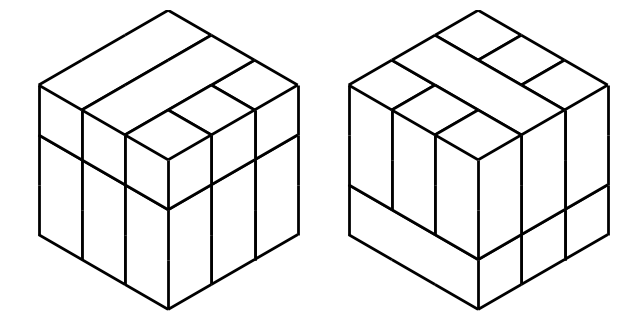

The bandage shape graph contains **306 shapes.**

In [2]:
import bce_v2 as c
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

reference = c.Shape([
    1, 2, 0,
    1, 2, 0,
    1, 2, 0,

    3, 4, 5,
    6, 4, 7,
    8, 4, 9,

    3, 4, 5,
    6, 4, 7,
    8, 4, 9,
])

figure = c.draw_cubes(reference, alpha=1, views = ("UFR", "BLD"))
plt.show()

shape_graph = c.explore(reference, metric="HTM")
assert shape_graph.complete
display(Markdown(f"The bandage shape graph contains **{len(shape_graph):,} shapes.**"))

## Visual navigation - small graphs only!

For graphs of up to a couple hundred of vertices (check previous cell output) you can hope to draw the graph and be able to locate your scramble visually and follow a turn sequence to the reference shape.

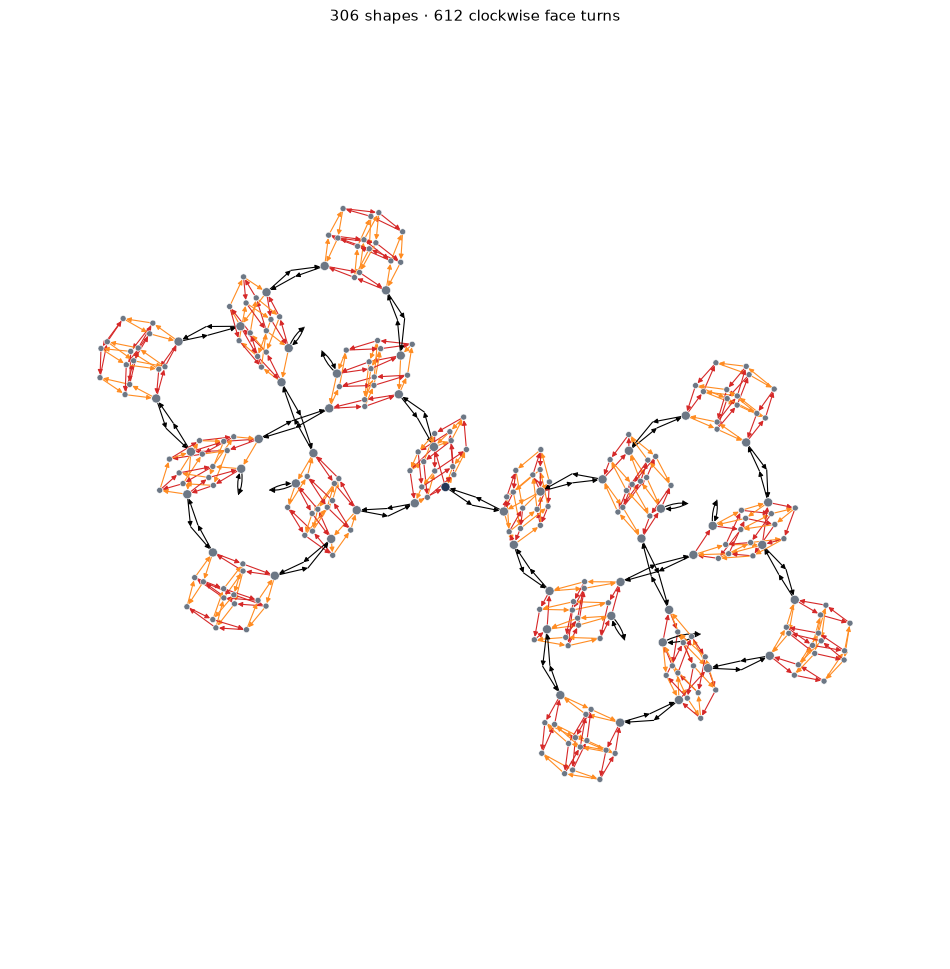

In [3]:
figure = shape_graph.draw(
    view="full", start=reference, show_shapes=False, edge_labels=False,
    figsize=(10, 10), shape_size=0.25,
    diagram_mode=c.DiagramMode.SINGLE_CORNER,
    layout="kamada_kawai", iterations=300
)
display(figure)
plt.close(figure)

## Solve shape

Input a scramble and get a shortest turn sequence to the reference shape.

In [21]:
scramble = c.Shape([
    1, 2, 2,
    3, 3, 3,
    4, 4, 4,
    
    5, 6, 7,
    8, 6, 7,
    9, 6, 10,
    
    5, 6, 11,
    8, 6, 12,
    9, 6, 12
])

solution = shape_graph.shortest_path(scramble, reference)
restored_shape = scramble.apply(solution)
assert restored_shape == reference

units = "quarter turns" if shape_graph.metric == "QTM" else "moves"
path_text = f"`{solution}`" if solution else "Already in the reference shape; no moves needed."
display(Markdown(
    f"**Shortest return ({shape_graph.metric}):** {path_text}\n\n"
))


**Shortest return (HTM):** `U' R2 U2 R2 U2 R`



## Generate a scramble

In [22]:
print(c.scramble(reference))


U2 R2 L2 R L2 R2 L' R2 L2 R' L2 R2 U2 R U2 L R' L' R2 L' R2 L' R U2 L R L R' U2 L2 R' U2 L' R L' R' U2 L' R' L U2 L' R2 L2 R2 L U2 L2 U2 L R L2 R L R L' R L' U2 R2 L R2 L U2 R' L' R L' U2 L R L2 R2 L R2 U2 R2 L R2 L2 R' L2
